Cвёрточный автоэнкодер для восстановления изображений MNIST

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader, Subset

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

image_size = 28
channels = 1
batch_size = 128

print("Device:", device)

Device: cuda


In [4]:
def get_dataloader(batch_size=128, N=30000):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    dataset = datasets.MNIST(
        root="./data",
        train=True,
        download=True,
        transform=transform
    )

    dataset = Subset(dataset, indices=range(N))

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    return loader

In [5]:
def show_real_images(loader):
    real_batch, _ = next(iter(loader))

    fig, ax = plt.subplots(figsize=(6, 6))
    grid = make_grid(real_batch[:64], nrow=8, normalize=True, value_range=(-1, 1))
    ax.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
    ax.axis("off")
    ax.set_title("Real MNIST")
    plt.show()

In [6]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [7]:
@torch.no_grad()
def show_autoencoder_results(model, images):
    model.eval()

    reconstructed = model(images[:64]).cpu()

    fig, ax = plt.subplots(figsize=(6, 6))
    grid = make_grid(reconstructed, nrow=8, normalize=True, value_range=(-1, 1))
    ax.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
    ax.axis("off")
    ax.set_title("Autoencoder")
    plt.show()

    model.train()

In [8]:
def train_autoencoder(model, train_loader, epochs=20):
    optimizer = optim.Adam(model.parameters(), lr=0.0002)
    criterion = nn.MSELoss()

    losses = []

    for epoch in range(epochs):
        total_loss = 0

        for images, _ in train_loader:
            images = images.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, images)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        losses.append(avg_loss)

        print(f"Epoch [{epoch+1}/{epochs}] Loss: {avg_loss:.4f}")

        if (epoch + 1) % 5 == 0:
            show_autoencoder_results(model, images)

    return losses

In [9]:
def plot_losses(losses, title="Loss"):
    plt.figure()
    plt.plot(losses)
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.show()

100%|██████████| 9.91M/9.91M [00:00<00:00, 44.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.14MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.99MB/s]


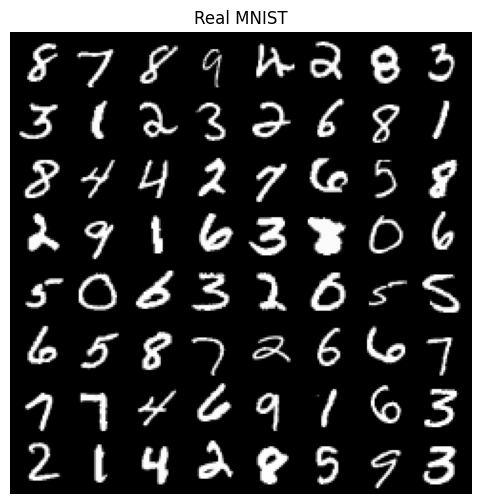

Epoch [1/20] Loss: 0.2253
Epoch [2/20] Loss: 0.0176
Epoch [3/20] Loss: 0.0093
Epoch [4/20] Loss: 0.0068
Epoch [5/20] Loss: 0.0055


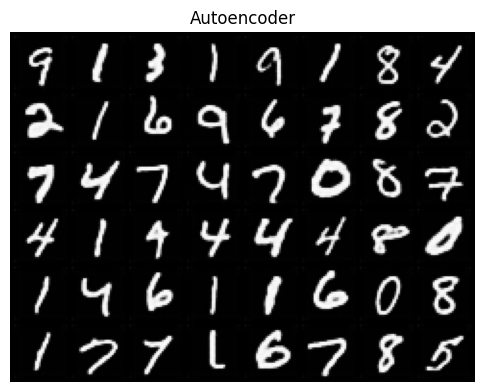

Epoch [6/20] Loss: 0.0047
Epoch [7/20] Loss: 0.0042
Epoch [8/20] Loss: 0.0038
Epoch [9/20] Loss: 0.0035
Epoch [10/20] Loss: 0.0032


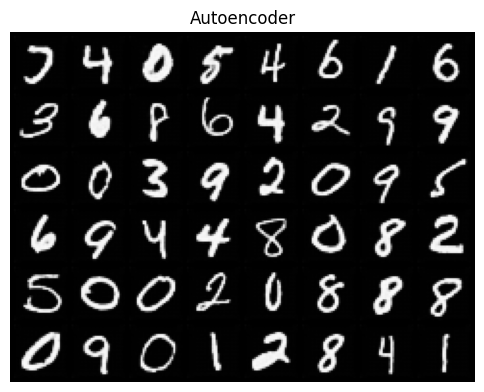

Epoch [11/20] Loss: 0.0030
Epoch [12/20] Loss: 0.0028
Epoch [13/20] Loss: 0.0027
Epoch [14/20] Loss: 0.0025
Epoch [15/20] Loss: 0.0024


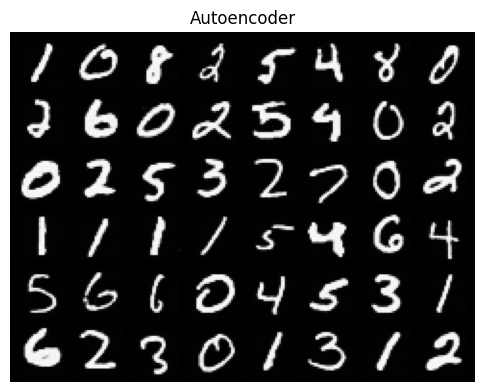

Epoch [16/20] Loss: 0.0023
Epoch [17/20] Loss: 0.0022
Epoch [18/20] Loss: 0.0022
Epoch [19/20] Loss: 0.0021
Epoch [20/20] Loss: 0.0020


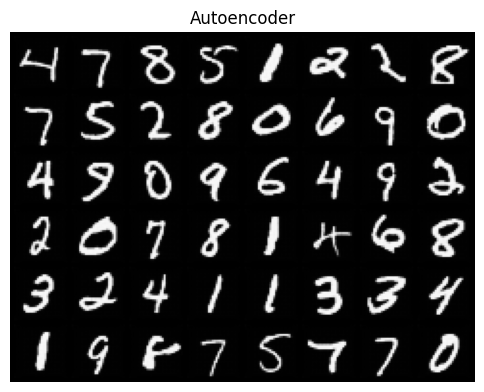

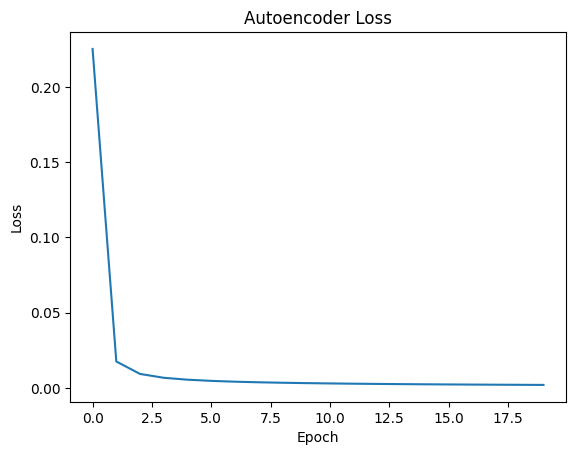

In [10]:

train_loader = get_dataloader(batch_size)

# 2. Показать реальные картинки
show_real_images(train_loader)

# 3. Модель
AE = Autoencoder().to(device)

# 4. Обучение
ae_losses = train_autoencoder(AE, train_loader, epochs=20)

# 5. График
plot_losses(ae_losses, "Autoencoder Loss")